# EDA (`explorar_proyecto.ipynb`)

**Objetivo:** Analizar la estructura, calidad, distribución del objetivo (`abandono_60d`), presencia de valores atípicos y relaciones estadísticas en el dataset limpio generado por el pipeline (`../data/processed/obt_riesgo_abandono.csv`), documentando al menos **tres hallazgos concretos con su evidencia y su impacto directo en las decisiones de modelado**.

**Problema:** clasificación binaria. 

**Momento de predicción:** al terminar una sesión; se usa solo lo que se sabe en ese instante.
Cualquier columna que se conozca después (o que codifique el desenlace) es fuga.

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

CANDIDATAS = [
    Path("../data/processed/obt_riesgo_abandono.csv"),
    Path("data/processed/obt_riesgo_abandono.csv"),
]
RUTA = next(p for p in CANDIDATAS if p.exists())
TARGET = "abandono_60d"
FECHAS = ["fecha_realizada", "fecha_inicio_plan"]

df = pd.read_csv(RUTA, parse_dates=FECHAS)
print("Archivo:", RUTA.resolve())
df.head()

Archivo: C:\Users\ANDRES\Desktop\proyecto_final\data\processed\obt_riesgo_abandono.csv


,sesion_key,paciente_key,plan_tratamiento_id,cita_id,odontologo_key,procedimiento_key,codigo_procedimiento,nombre_procedimiento,duracion_estimada_min,fecha_realizada,fecha_inicio_plan,numero_sesion,sesiones_planificadas,sesiones_previas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,dia_semana_atencion,mes_atencion,abandono_60d
0,2,4,2,174,2,8,WHITEN,Whitening session,60,2024-11-08,2024-11-08,1,2,0,0,0,0,72,5,11,1
1,6,6,4,177,4,9,ROOT,"Root canal, molar",90,2025-08-19,2025-07-27,1,4,0,1,0,23,52,2,8,0
2,8,6,4,178,4,9,ROOT,"Root canal, molar",90,2025-09-26,2025-07-27,2,4,1,2,0,61,52,5,9,0
3,13,6,5,181,4,10,CROWN,Porcelain crown,75,2025-01-31,2025-01-31,1,3,0,0,0,0,52,5,1,0
4,14,6,5,182,4,10,CROWN,Porcelain crown,75,2025-03-07,2025-01-31,2,3,1,0,0,35,52,5,3,1


Cada fila es una sesión clínica realizada. Las fechas se leyeron bien.

## 1. Resumen del dataset

In [16]:
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(2),
    "únicos": df.nunique(),
})
display(resumen)
print("Filas duplicadas (completas):", df.duplicated().sum())
print("Rango fecha_realizada:", df["fecha_realizada"].min().date(), "→", df["fecha_realizada"].max().date())

Filas: 2,377 | Columnas: 21


,dtype,faltantes,% faltantes,únicos
sesion_key,int64,0,0.0,2377
paciente_key,int64,0,0.0,1287
plan_tratamiento_id,int64,0,0.0,1576
cita_id,int64,0,0.0,2377
odontologo_key,int64,0,0.0,5
procedimiento_key,int64,0,0.0,6
codigo_procedimiento,str,0,0.0,6
nombre_procedimiento,str,0,0.0,6
duracion_estimada_min,int64,0,0.0,6
fecha_realizada,datetime64[us],0,0.0,500


Filas duplicadas (completas): 0
Rango fecha_realizada: 2024-01-02 → 2025-11-01


* 2,377 filas y 21 columnas, sin faltantes ni duplicados. Fechas de enero 2024 a noviembre 2025.
* Los IDs (`sesion_key`, `cita_id`, `plan_tratamiento_id`, `paciente_key`) no son predictores.
* `procedimiento_key`, `codigo_procedimiento` y `nombre_procedimiento` son lo mismo: se usa una sola.

In [17]:
# Clasificación de columnas (identificadores vs numéricas vs categóricas)
IDS = ["sesion_key", "paciente_key", "plan_tratamiento_id", "cita_id",
       "odontologo_key", "procedimiento_key"]
CATEG = ["codigo_procedimiento", "nombre_procedimiento"]
NUM = [c for c in df.select_dtypes("number").columns if c not in IDS + [TARGET]]
print("Numéricas:", NUM)
display(df[NUM].describe().T.round(2))
display(df[CATEG + ["odontologo_key"]].nunique().to_frame("únicos"))
display(df["codigo_procedimiento"].value_counts().to_frame("filas"))

Numéricas: ['duracion_estimada_min', 'numero_sesion', 'sesiones_planificadas', 'sesiones_previas', 'cancelaciones_previas', 'inasistencias_previas', 'dias_desde_inicio_plan', 'edad_en_atencion', 'dia_semana_atencion', 'mes_atencion']


,count,mean,std,min,25%,50%,75%,max
duracion_estimada_min,2377.0,67.05,18.70,30.0,50.0,75.0,90.0,90.0
numero_sesion,2377.0,1.42,0.64,1.0,1.0,1.0,2.0,3.0
sesiones_planificadas,2377.0,3.00,0.82,2.0,2.0,3.0,4.0,4.0
sesiones_previas,2377.0,0.42,0.64,0.0,0.0,0.0,1.0,2.0
cancelaciones_previas,2377.0,0.10,0.33,0.0,0.0,0.0,0.0,2.0
inasistencias_previas,2377.0,0.06,0.27,0.0,0.0,0.0,0.0,3.0
dias_desde_inicio_plan,2377.0,14.51,21.93,0.0,0.0,0.0,26.0,119.0
edad_en_atencion,2377.0,44.21,21.10,6.0,26.0,45.0,63.0,80.0
dia_semana_atencion,2377.0,3.15,1.82,1.0,1.0,3.0,5.0,6.0
mes_atencion,2377.0,7.06,2.90,1.0,5.0,8.0,9.0,12.0


,únicos
codigo_procedimiento,6
nombre_procedimiento,6
odontologo_key,5


,filas
codigo_procedimiento,
ROOT,647
CROWN,570
WHITEN,519
FILL2,314
FILL1,175
EXTRACT,152


* Edad y duración están bien repartidas, sin valores raros.
* Cancelaciones, inasistencias y días desde el inicio son casi siempre 0, con pocos valores altos.
* Los 6 procedimientos tienen suficientes casos (el menor tiene 152).

## 2. Integridad y estructura (qué significa cada fila y qué grupos hay)

In [18]:
chk = {}
chk["sesion_key única"] = df["sesion_key"].is_unique
chk["sesiones_previas == numero_sesion-1 (% filas)"] = round((df["sesiones_previas"] == df["numero_sesion"] - 1).mean() * 100, 2)
dias_calc = (df["fecha_realizada"] - df["fecha_inicio_plan"]).dt.days
chk["dias_desde_inicio_plan == diferencia de fechas (%)"] = round((df["dias_desde_inicio_plan"] == dias_calc).mean() * 100, 2)
chk["dia_semana_atencion == isoweekday (%)"] = round((df["dia_semana_atencion"] == df["fecha_realizada"].dt.dayofweek + 1).mean() * 100, 2)
chk["mes_atencion == mes de fecha (%)"] = round((df["mes_atencion"] == df["fecha_realizada"].dt.month).mean() * 100, 2)
chk["numero_sesion <= sesiones_planificadas (%)"] = round((df["numero_sesion"] <= df["sesiones_planificadas"]).mean() * 100, 2)
chk["fecha_realizada >= fecha_inicio_plan (%)"] = round((dias_calc >= 0).mean() * 100, 2)
display(pd.Series(chk, name="resultado").to_frame())

g_pac = df.groupby("paciente_key").size()
g_plan = df.groupby("plan_tratamiento_id").size()
print(f"Pacientes: {g_pac.shape[0]:,} | filas por paciente: media {g_pac.mean():.2f}, máx {g_pac.max()}")
print(f"Planes: {g_plan.shape[0]:,} | filas por plan: media {g_plan.mean():.2f}, máx {g_plan.max()}")
print(f"% filas de pacientes con más de una fila: {(df['paciente_key'].map(g_pac) > 1).mean()*100:.1f}%")

C:\Users\ANDRES\AppData\Local\Temp\ipykernel_6424\1608659658.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chk["dia_semana_atencion == isoweekday (%)"] = round((df["dia_semana_atencion"] == df["fecha_realizada"].dt.dayofweek + 1).mean() * 100, 2)


,resultado
sesion_key única,True
sesiones_previas == numero_sesion-1 (% filas),100.0
dias_desde_inicio_plan == diferencia de fechas (%),100.0
dia_semana_atencion == isoweekday (%),100.0
mes_atencion == mes de fecha (%),100.0
numero_sesion <= sesiones_planificadas (%),100.0
fecha_realizada >= fecha_inicio_plan (%),100.0


Pacientes: 1,287 | filas por paciente: media 1.85, máx 7
Planes: 1,576 | filas por plan: media 1.51, máx 3
% filas de pacientes con más de una fila: 73.7%


* Las columnas derivadas (sesiones previas, días desde inicio, día, mes) cuadran con las fechas en el 100% de las filas.
* Las 2,377 sesiones son de 1,287 pacientes. El 74% de las filas son de pacientes con más de una sesión.

## 3. Target: distribución, desbalance y su comportamiento en el tiempo

              filas    pct
abandono_60d              
0               905  38.07
1              1472  61.93
Tasa de abandono: 0.619 | razón mayoritaria/minoritaria: 1.63:1


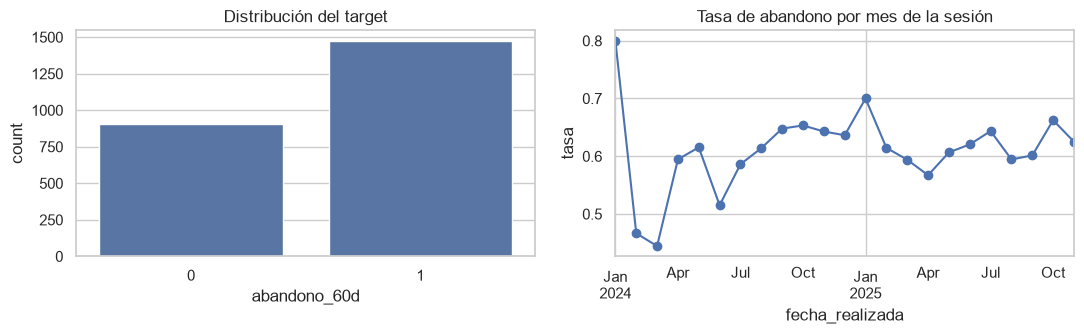

fecha_realizada,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11
tasa,0.8,0.467,0.444,0.595,0.615,0.515,0.586,0.614,0.648,0.653,0.643,0.636,0.7,0.615,0.594,0.567,0.607,0.62,0.644,0.594,0.601,0.662,0.625
filas,5.0,15.000,18.000,37.000,39.000,33.000,58.000,57.000,71.000,75.000,84.000,88.000,90.0,96.000,133.000,134.000,150.000,166.00,202.000,217.000,281.000,320.000,8.000


In [19]:
vc = df[TARGET].value_counts().sort_index()
tasa = df[TARGET].mean()
print(vc.to_frame("filas").assign(pct=(vc / len(df) * 100).round(2)))
print(f"Tasa de abandono: {tasa:.3f} | razón mayoritaria/minoritaria: {vc.max()/vc.min():.2f}:1")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title("Distribución del target")
mensual = df.groupby(df["fecha_realizada"].dt.to_period("M"))[TARGET].agg(["mean", "size"])
mensual["mean"].plot(ax=ax[1], marker="o"); ax[1].set_title("Tasa de abandono por mes de la sesión")
ax[1].set_ylabel("tasa"); plt.tight_layout(); plt.show()
display(mensual.rename(columns={"mean": "tasa", "size": "filas"}).round(3).T)

* 62% abandona y 38% continúa. Predecir siempre «abandona» acierta 62%, ese será el modelo ingenuo a superar.
* Desde el tercer trimestre de 2024 la tasa se mantiene entre 60% y 66%. Antes hay muy pocos datos.

In [20]:
# ¿El target es constante dentro de un paciente o plan? 
for g in ["paciente_key", "plan_tratamiento_id"]:
    n = df.groupby(g)[TARGET].nunique()
    print(f"{g}: grupos con target mixto (0 y 1) = {(n > 1).sum()} de {len(n)} ({(n > 1).mean()*100:.1f}%)")

# ¿Dónde cae el abandono dentro del plan?
df["es_ultima_planificada"] = df["numero_sesion"] == df["sesiones_planificadas"]
df["es_ultima_observada"] = df["numero_sesion"] == df.groupby("plan_tratamiento_id")["numero_sesion"].transform("max")
display(df.groupby("es_ultima_planificada")[TARGET].agg(["mean", "size"]).round(3))
display(df.groupby("es_ultima_observada")[TARGET].agg(["mean", "size"]).round(3))

# Censura a la derecha: sesiones cuya ventana de 60 días no terminó dentro del dataset
corte = df["fecha_realizada"].max() - pd.Timedelta(days=60)
df["ventana_incompleta"] = df["fecha_realizada"] > corte
display(df.groupby("ventana_incompleta")[TARGET].agg(["mean", "size"]).round(3))
print("Fecha de corte (max - 60d):", corte.date())

paciente_key: grupos con target mixto (0 y 1) = 551 de 1287 (42.8%)
plan_tratamiento_id: grupos con target mixto (0 y 1) = 562 de 1576 (35.7%)


,mean,size
es_ultima_planificada,,
False,0.619,2377


,mean,size
es_ultima_observada,,
False,0.005,801
True,0.931,1576


,mean,size
ventana_incompleta,,
False,0.614,1799
True,0.637,578


Fecha de corte (max - 60d): 2025-09-02


* Un mismo paciente puede tener sesiones con abandono 0 y con 1, así que el abandono se predice por sesión.
* Si la sesión tiene otra sesión después del mismo plan, el abandono es casi siempre 0 (0.5%). Si es la última del plan en el dataset, casi siempre es 1 (93%). La etiqueta se parece mucho a «no hubo una sesión siguiente» (ver hallazgo 1).
* Ninguna fila es la última sesión planificada, esas sesiones no están en el dataset.
* Últimos 60 días: 64% de abandono contra 61% antes. No se ve diferencia.

## 4. Valores atípicos: IQR (boxplot) y Z-score ≥ 3

,min,p50,p99,max,lim_inf_IQR,lim_sup_IQR,n_IQR,%_IQR,n_Z>=3,%_Z>=3
variable,,,,,,,,,,
duracion_estimada_min,30,75.0,90.00,90,-10.0,150.0,0,0.00,0,0.00
numero_sesion,1,1.0,3.00,3,-0.5,3.5,0,0.00,0,0.00
sesiones_planificadas,2,3.0,4.00,4,-1.0,7.0,0,0.00,0,0.00
sesiones_previas,0,0.0,2.00,2,-1.5,2.5,0,0.00,0,0.00
cancelaciones_previas,0,0.0,2.00,2,0.0,0.0,209,8.79,25,1.05
inasistencias_previas,0,0.0,1.00,3,0.0,0.0,139,5.85,139,5.85
dias_desde_inicio_plan,0,0.0,87.24,119,-39.0,65.0,100,4.21,37,1.56
edad_en_atencion,6,45.0,79.00,80,-29.5,118.5,0,0.00,0,0.00
dia_semana_atencion,1,3.0,6.00,6,-5.0,11.0,0,0.00,0,0.00


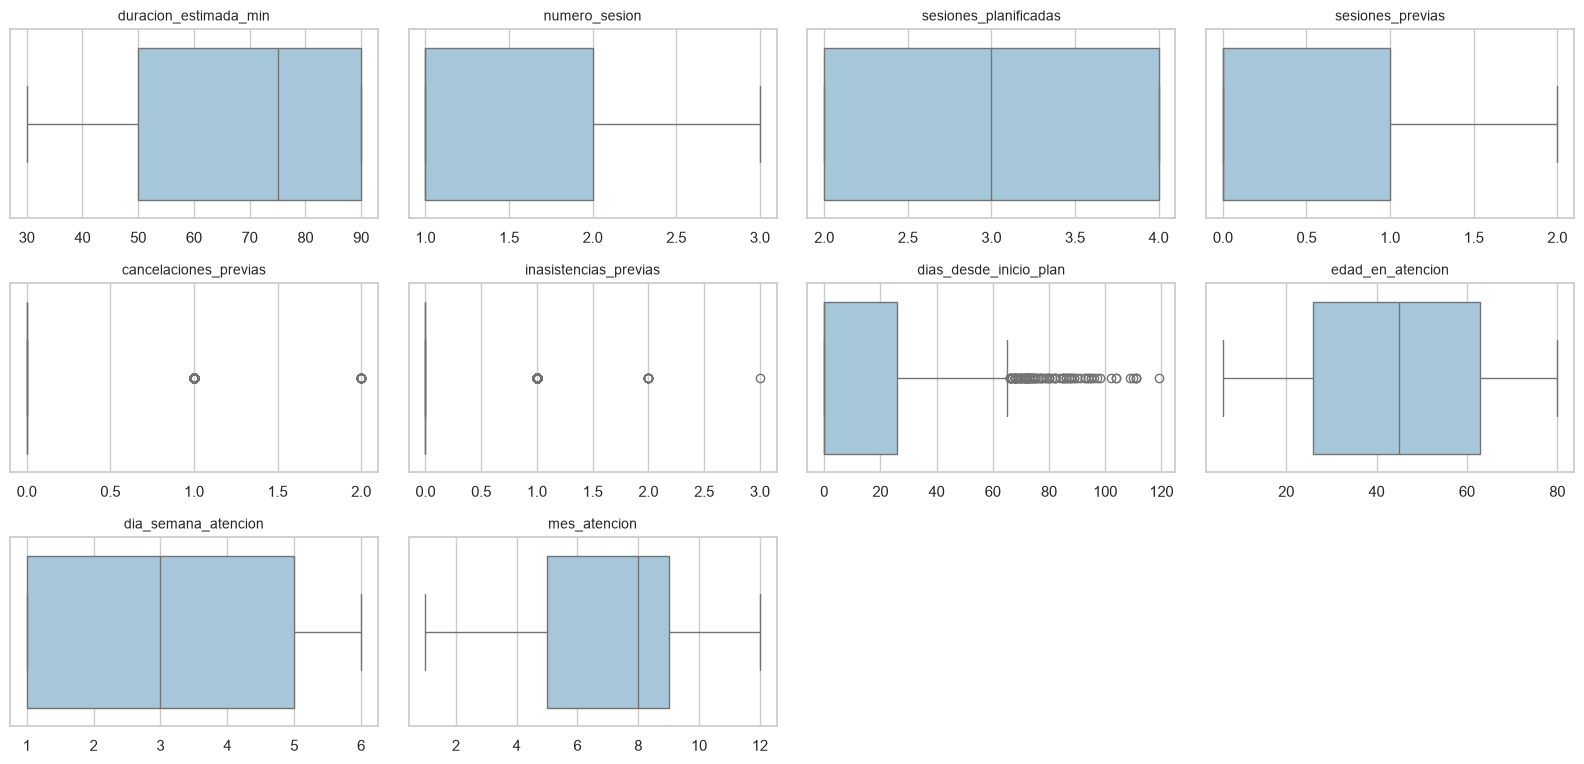

In [21]:
filas = []
for c in NUM:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((s < lo) | (s > hi)).sum()
    z = np.abs(stats.zscore(s)) if s.std() > 0 else np.zeros(len(s))
    filas.append({"variable": c, "min": s.min(), "p50": s.median(), "p99": s.quantile(.99), "max": s.max(),
                  "lim_inf_IQR": lo, "lim_sup_IQR": hi, "n_IQR": n_iqr, "%_IQR": round(n_iqr / len(s) * 100, 2),
                  "n_Z>=3": int((z >= 3).sum()), "%_Z>=3": round((z >= 3).mean() * 100, 2)})
atip = pd.DataFrame(filas).set_index("variable").round(2)
display(atip)

cols = NUM
n = len(cols); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(x=df[c], ax=ax, color="#9ecae1"); ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

* Solo cancelaciones, inasistencias y días desde el inicio tienen valores fuera de rango.
* Son valores reales (hasta 3 faltas, hasta 119 días). No se eliminan.
* En cancelaciones e inasistencias el límite IQR es 0 porque casi todos son 0, por eso marca tantos.

,skew
inasistencias_previas,4.56
cancelaciones_previas,3.53
dias_desde_inicio_plan,1.63
numero_sesion,1.25
sesiones_previas,1.25
dia_semana_atencion,0.24
sesiones_planificadas,-0.00
edad_en_atencion,-0.02
duracion_estimada_min,-0.31
mes_atencion,-0.41


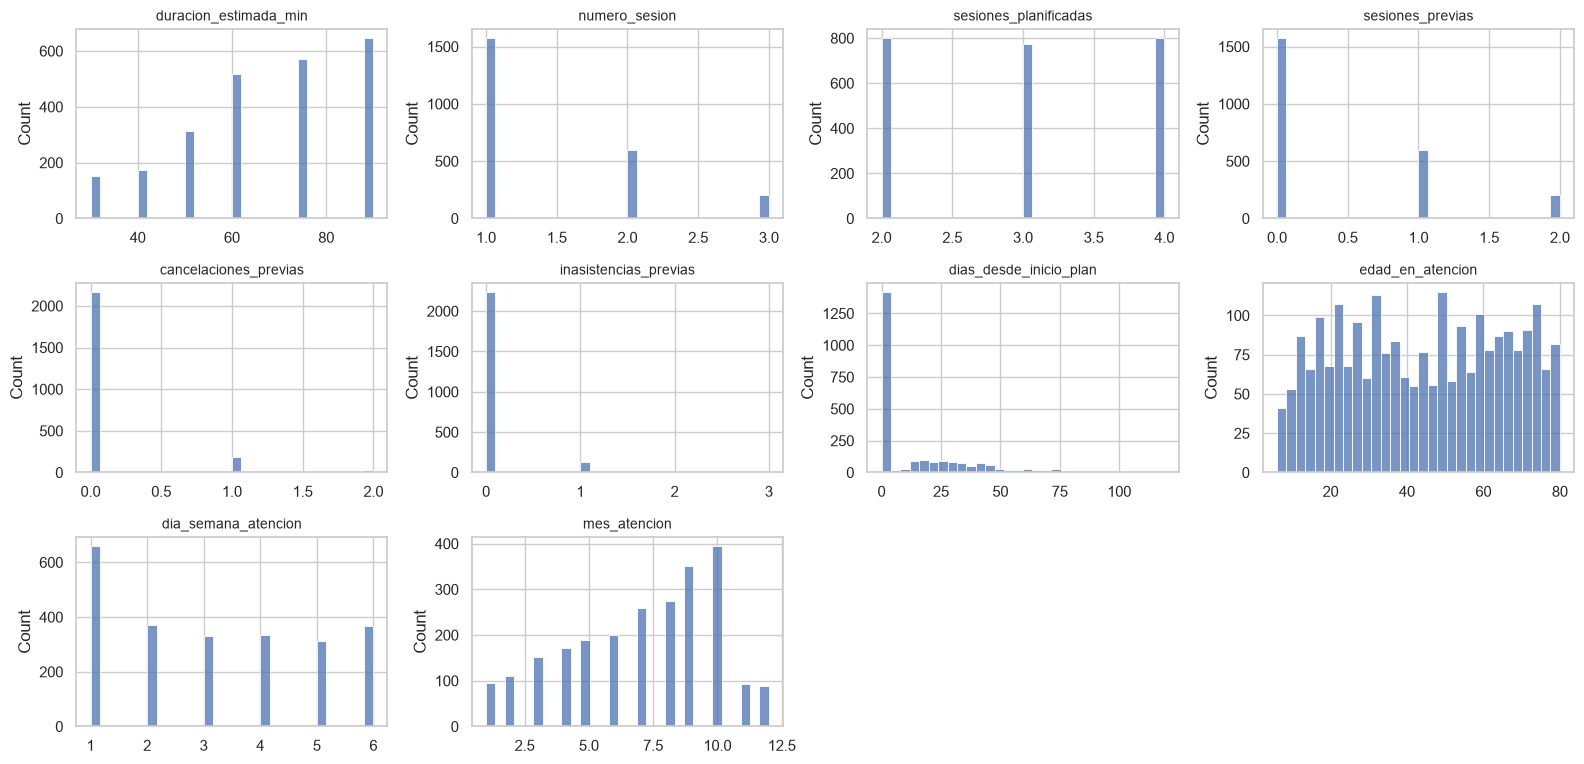

In [22]:
# Asimetría y forma de las variables de conteo / duración
display(df[NUM].skew().round(2).sort_values(ascending=False).to_frame("skew"))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=30, ax=ax); ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

* Cancelaciones, inasistencias y días desde el inicio están muy cargadas hacia valores bajos.
* **Consecuencia:** en el modelo lineal y la red neuronal se escalan con `RobustScaler`. Los árboles no lo necesitan.

## 5. Relación entre el target y las características

Se usa **Spearman** debido a que casi todas las variables son conteos o discretas, con asimetría y atípicos; Spearman es robusto a ambos y capta relaciones monótonas no lineales. Con target binario equivale a una correlación de rangos punto-biserial. Pearson se muestra solo como contraste.

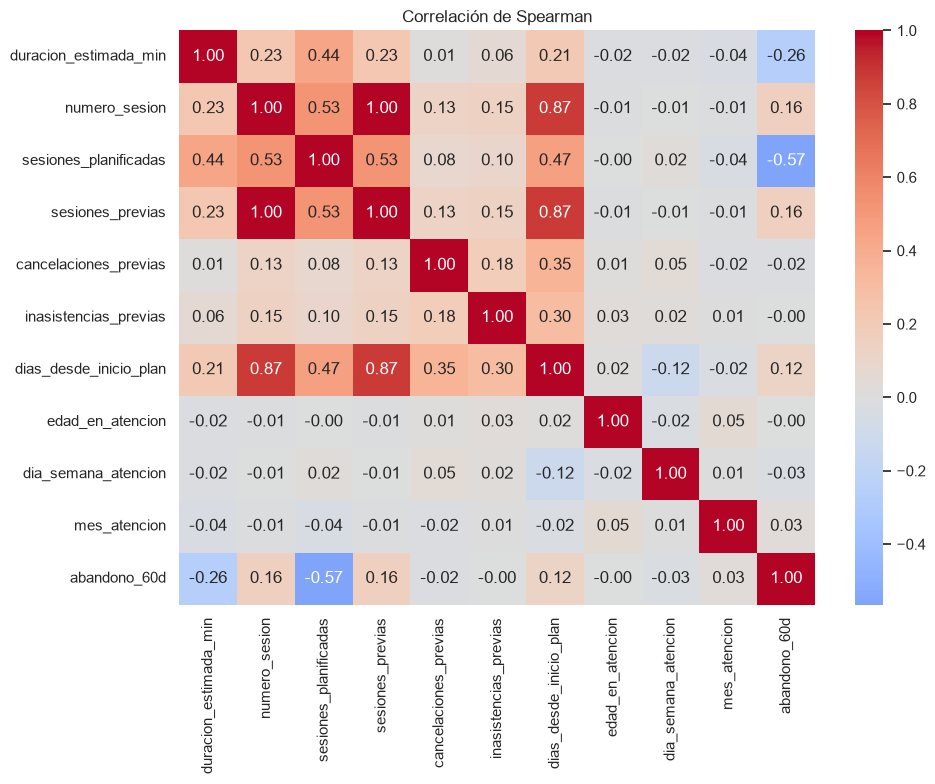

,spearman,pearson,|spearman|
sesiones_planificadas,-0.565,-0.565,0.565
duracion_estimada_min,-0.259,-0.274,0.259
numero_sesion,0.161,0.196,0.161
sesiones_previas,0.161,0.196,0.161
dias_desde_inicio_plan,0.123,0.168,0.123
mes_atencion,0.028,0.022,0.028
dia_semana_atencion,-0.027,-0.027,0.027
cancelaciones_previas,-0.015,-0.002,0.015
edad_en_atencion,-0.002,-0.001,0.002
inasistencias_previas,-0.000,0.005,0.000


,level_0,level_1,rho
13,numero_sesion,sesiones_previas,1.000
16,numero_sesion,dias_desde_inicio_plan,0.873
36,sesiones_previas,dias_desde_inicio_plan,0.873


In [23]:
corr_s = df[NUM + [TARGET]].corr(method="spearman")
corr_p = df[NUM + [TARGET]].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación de Spearman"); plt.tight_layout(); plt.show()

tab = pd.DataFrame({"spearman": corr_s[TARGET], "pearson": corr_p[TARGET]}).drop(TARGET)
tab["|spearman|"] = tab["spearman"].abs()
tab = tab.sort_values("|spearman|", ascending=False)
display(tab.round(3))

# Colinealidad entre predictores (|rho| >= 0.8)
pares = (corr_s.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(NUM), len(NUM))), 1).astype(bool))
        .stack().rename("rho").reset_index())
display(pares[pares["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False).round(3))

* La variable más relacionada con el abandono es `sesiones_planificadas` (−0.57): a más sesiones planeadas, menos abandono.
* Le sigue `duracion_estimada_min` (−0.26), que en realidad depende del tipo de procedimiento.
* Edad, inasistencias y cancelaciones casi no se relacionan por sí solas.
* `numero_sesion` y `sesiones_previas` son la misma información (correlación 1.00): se deja solo una.

## 6. Relación del target con la variable que se espera que más influya

Variable con mayor |Spearman| frente al target: sesiones_planificadas


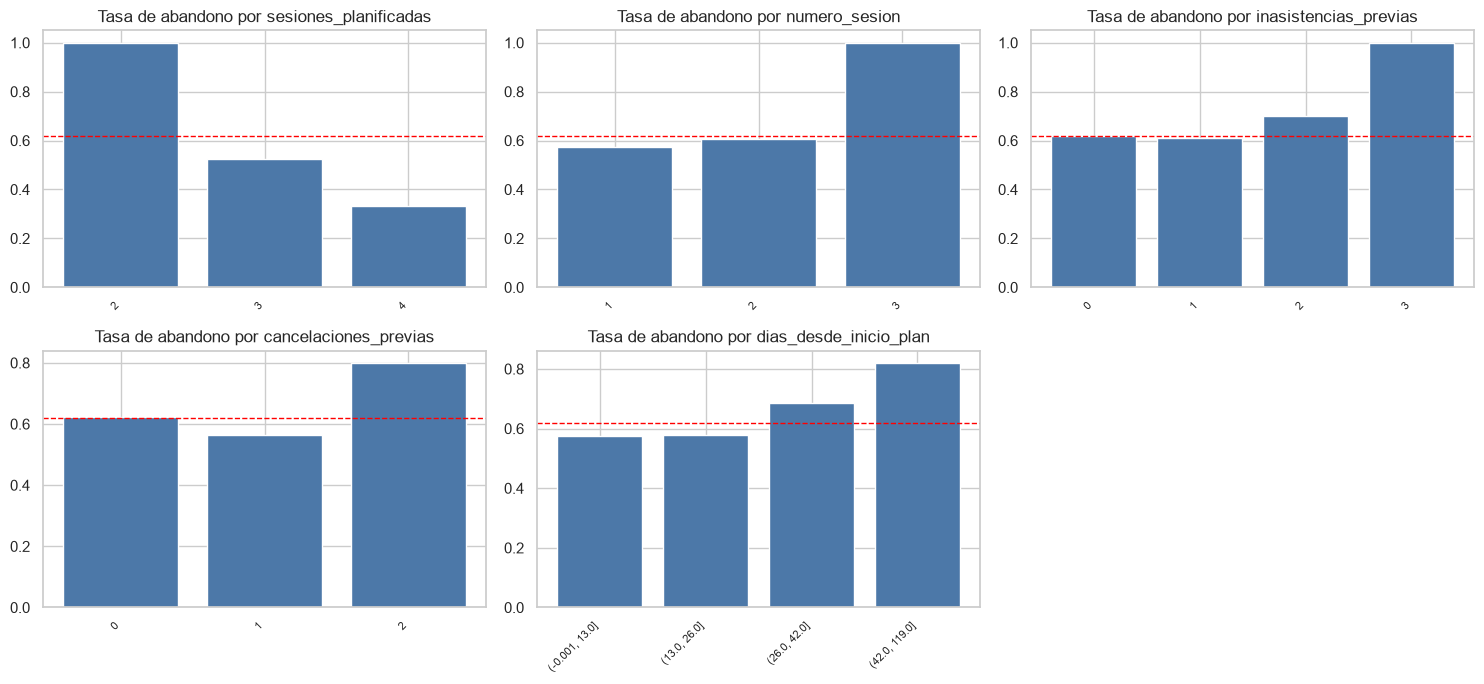

,tasa,n
sesiones_planificadas,,
2,1.000,800
3,0.524,776
4,0.331,801


In [24]:
top = tab.index[0]
print("Variable con mayor |Spearman| frente al target:", top)

def tasa_por(df, col, q=None):
    x = df[col]
    if q and x.nunique() > 12:
        x = pd.qcut(x, q=q, duplicates="drop")
    return df.groupby(x, observed=True)[TARGET].agg(tasa="mean", n="size")

vars_clave = list(dict.fromkeys([top, "numero_sesion", "inasistencias_previas", "cancelaciones_previas",
                                "dias_desde_inicio_plan", "sesiones_planificadas"]))
vars_clave = [v for v in vars_clave if v in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.ravel(), vars_clave):
    t = tasa_por(df, v, q=8)
    ax.bar(range(len(t)), t["tasa"], color="#4c78a8")
    ax.set_xticks(range(len(t))); ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=8)
    ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1); ax.set_title(f"Tasa de abandono por {v}")
for ax in axes.ravel()[len(vars_clave):]: ax.axis("off")
plt.tight_layout(); plt.show()
display(tasa_por(df, top, q=8).round(3))

* Planes de 2 sesiones: **100%** abandona (800 filas). Planes de 3: 52%. Planes de 4: 33%.
* Esto no refleja el comportamiento del paciente: se explica por cómo está armado el dataset (hallazgo 1).
* Con 2 o 3 inasistencias y con más de 42 días el abandono sube, pero son pocos casos y se mezcla con el avance del plan.

In [25]:
# Progreso en el plan y tasa por procedimiento / día / mes
df["progreso_plan"] = df["numero_sesion"] / df["sesiones_planificadas"]
display(tasa_por(df, "progreso_plan", q=5).round(3))
for c in ["codigo_procedimiento", "dia_semana_atencion", "mes_atencion", "odontologo_key"]:
    print(f"\n— {c}")
    display(tasa_por(df, c).round(3).T)

# Prueba estadística simple para la variable top (Mann-Whitney entre clases)
a = df.loc[df[TARGET] == 1, top]; b = df.loc[df[TARGET] == 0, top]
u = stats.mannwhitneyu(a, b)
print(f"Mann-Whitney {top}: p = {u.pvalue:.3g} | mediana abandona = {a.median()} vs no abandona = {b.median()}")

,tasa,n
progreso_plan,,
0.250000,0.104,335
0.333333,0.163,441
0.500000,0.778,1064
0.666667,1.000,335
0.750000,1.000,202



— codigo_procedimiento


codigo_procedimiento,CROWN,EXTRACT,FILL1,FILL2,ROOT,WHITEN
tasa,0.537,1.0,1.0,0.71,0.524,0.534
n,570.000,152.0,175.0,314.00,647.000,519.000



— dia_semana_atencion


dia_semana_atencion,1,2,3,4,5,6
tasa,0.635,0.616,0.634,0.613,0.617,0.589
n,660.000,372.000,331.000,336.000,311.000,367.000



— mes_atencion


mes_atencion,1,2,3,4,5,6,7,8,9,10,11,12
tasa,0.705,0.595,0.576,0.573,0.608,0.603,0.631,0.599,0.611,0.661,0.641,0.636
n,95.000,111.000,151.000,171.000,189.000,199.000,260.000,274.000,352.000,395.000,92.000,88.000



— odontologo_key


odontologo_key,1,2,3,4,5
tasa,0.603,0.614,0.662,0.629,0.594
n,446.000,466.000,435.000,501.000,529.000


Mann-Whitney sesiones_planificadas: p = 3.23e-167 | mediana abandona = 2.0 vs no abandona = 4.0


* Primeras sesiones del plan: abandono de **10% a 16%**.
* Penúltima sesión del plan (2/3 y 3/4): **100%**.
* `EXTRACT` y `FILL1` (planes de 2 sesiones): 100%.
* Día de la semana, mes y odontólogo casi no cambian el abandono (59% a 66%).

## 7. Candidatos a hallazgos (revisión de fuga, grupos y tiempo)

In [26]:
hall = {}
# a) ¿El target depende del avance del plan de forma determinista? (posible fuga / regla trivial)
hall["tasa en última sesión planificada"] = df.loc[df["es_ultima_planificada"], TARGET].mean()
hall["tasa en sesiones no finales"] = df.loc[~df["es_ultima_planificada"], TARGET].mean()
# b) Censura a la derecha
hall["tasa con ventana completa"] = df.loc[~df["ventana_incompleta"], TARGET].mean()
hall["tasa con ventana incompleta"] = df.loc[df["ventana_incompleta"], TARGET].mean()
hall["% filas con ventana incompleta"] = df["ventana_incompleta"].mean() * 100
# c) Dependencia entre filas del mismo paciente (necesidad de GroupKFold)
hall["% filas en pacientes con >1 fila"] = (df["paciente_key"].map(g_pac) > 1).mean() * 100
hall["filas por paciente (media)"] = g_pac.mean()
# d) Desbalance
hall["tasa de abandono"] = tasa
# e) Atípicos
hall["variable con más atípicos IQR"] = atip["%_IQR"].idxmax() + f" ({atip['%_IQR'].max()}%)"
display(pd.Series(hall, name="valor").to_frame())

# Cobertura temporal del target y volumen por periodo (para decidir el esquema de división)
display(df.groupby(df["fecha_realizada"].dt.to_period("Q"))[TARGET].agg(tasa="mean", filas="size").round(3).T)

,valor
tasa en última sesión planificada,NaN
tasa en sesiones no finales,0.619268
tasa con ventana completa,0.613674
tasa con ventana incompleta,0.636678
% filas con ventana incompleta,24.316365
% filas en pacientes con >1 fila,73.706353
filas por paciente (media),1.846931
tasa de abandono,0.619268
variable con más atípicos IQR,cancelaciones_previas (8.79%)


fecha_realizada,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
tasa,0.5,0.578,0.618,0.644,0.63,0.6,0.611,0.662
filas,38.0,109.000,186.000,247.000,319.00,450.0,700.000,328.000


* Por trimestre, la tasa de abandono se mantiene entre 60% y 66% desde 2024-T3.
* El 74% de las filas son de pacientes repetidos: la validación debe agrupar por paciente.

### 7.1 Verificación del hallazgo 1: sesiones que quedan en el plan

In [27]:

df["sesiones_restantes"] = df["sesiones_planificadas"] - df["numero_sesion"]
display(df.groupby("sesiones_restantes")[TARGET].agg(tasa="mean", filas="size").round(3))
display(df.groupby(["sesiones_planificadas", "numero_sesion"])[TARGET].agg(tasa="mean", filas="size").round(3))

# Regla simple: abandona si falta exactamente 1 sesión
pred = (df["sesiones_restantes"] == 1).astype(int)
acc = (pred == df[TARGET]).mean()
rec = (pred[df[TARGET] == 1] == 1).mean()
prec = df.loc[pred == 1, TARGET].mean()
print(f"Regla 'falta 1 sesión' -> accuracy {acc:.3f} | recall {rec:.3f} | precisión {prec:.3f}")


,tasa,filas
sesiones_restantes,,
1,1.000,1337
2,0.142,705
3,0.104,335


tasa  filas
sesiones_planificadas numero_sesion              
2                     1              1.000    800
3                     1              0.163    441
                      2              1.000    335
4                     1              0.104    335
                      2              0.106    264
                      3              1.000    202

Regla 'falta 1 sesión' -> accuracy 0.943 | recall 0.908 | precisión 1.000


* Cuando falta 1 sesión del plan, el abandono es **100%** (1,337 filas). Cuando faltan 2 o 3, es de **14%** y **10%**.
* Una sola regla («abandona si falta 1 sesión») acierta **94.3%**, con precisión 100% y recall 90.8%.
* Predecir siempre «abandona» acierta 62%. Esta regla acierta 94%, así que ese es el nuevo modelo ingenuo a superar.
* Los 135 abandonos que la regla no detecta están en sesiones donde faltan 2 o 3. Ahí está el comportamiento real del paciente.

,tasa,n
sesiones_restantes,,
1,1.000,1337
2,0.142,705
3,0.104,335


Regla 'falta 1 sesión' -> Exactitud: 94.3% | Precisión: 100.0% | Recall: 90.8%
inasistencias_previas >= 2 -> tasa=72.7% (n=11)
dias_desde_inicio_plan > 42 -> tasa=82.0% (n=284)


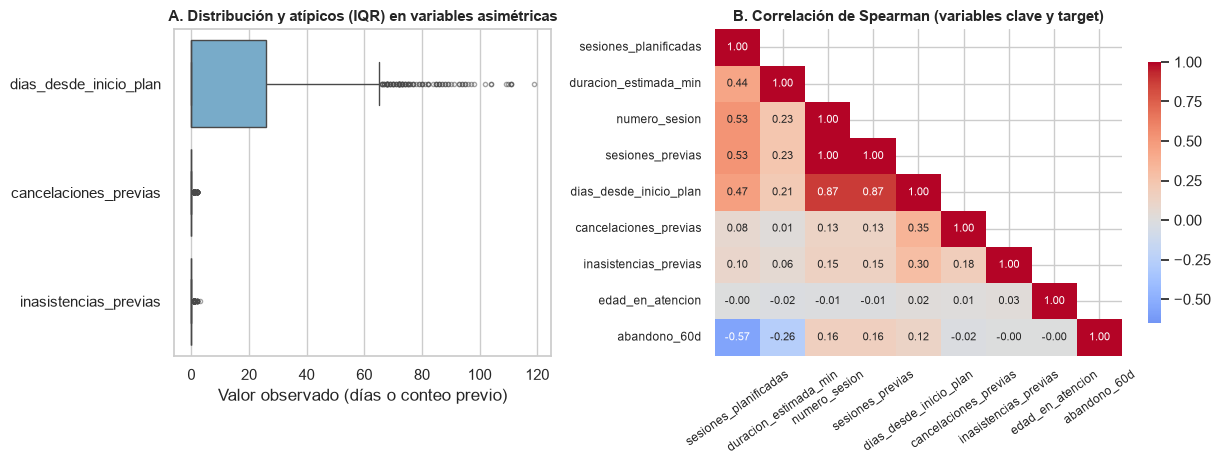

In [28]:
# Verificación numérica explícita para los Hallazgos 1 y 2 + Figura 1 del informe técnico
df["sesiones_restantes"] = df["sesiones_planificadas"] - df["numero_sesion"]
res_restantes = df.groupby("sesiones_restantes")[TARGET].agg(tasa="mean", n="size").round(3)
display(res_restantes)

pred_regla_1ses = (df["sesiones_restantes"] == 1).astype(int)
acc_1ses = (pred_regla_1ses == df[TARGET]).mean()
prec_1ses = df.loc[pred_regla_1ses == 1, TARGET].mean()
rec_1ses = df.loc[df[TARGET] == 1, "sesiones_restantes"].eq(1).mean()
print(f"Regla 'falta 1 sesión' -> Exactitud: {acc_1ses:.1%} | Precisión: {prec_1ses:.1%} | Recall: {rec_1ses:.1%}")

sub_inas = df.loc[df["inasistencias_previas"] >= 2, TARGET]
sub_dias = df.loc[df["dias_desde_inicio_plan"] > 42, TARGET]
print(f"inasistencias_previas >= 2 -> tasa={sub_inas.mean():.1%} (n={len(sub_inas)})")
print(f"dias_desde_inicio_plan > 42 -> tasa={sub_dias.mean():.1%} (n={len(sub_dias)})")

# Figura 1 compuesta (2 paneles equilibrados) para el documento técnico
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.35]})

# Panel izquierdo: Boxplots horizontales (IQR) de las 3 variables con asimetría derecha
vars_asim = ["dias_desde_inicio_plan", "cancelaciones_previas", "inasistencias_previas"]
df_melt = df[vars_asim].melt(var_name="Variable", value_name="Valor")
sns.boxplot(
    data=df_melt,
    x="Valor",
    y="Variable",
    ax=axes[0],
    palette=["#6baed6", "#fd8d3c", "#e6550d"],
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.5},
    hue="Variable",
    legend=False
)
axes[0].set_title("A. Distribución y atípicos (IQR) en variables asimétricas", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Valor observado (días o conteo previo)")
axes[0].set_ylabel("")

# Panel derecho: Heatmap de Spearman enfocado en variables clave + target
cols_corr = [
    "sesiones_planificadas",
    "duracion_estimada_min",
    "numero_sesion",
    "sesiones_previas",
    "dias_desde_inicio_plan",
    "cancelaciones_previas",
    "inasistencias_previas",
    "edad_en_atencion",
    TARGET,
]
corr_sp = df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr_sp, dtype=bool), k=1)
sns.heatmap(
    corr_sp,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-0.65,
    vmax=1.0,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8},
    ax=axes[1],
)
axes[1].set_title("B. Correlación de Spearman (variables clave y target)", fontsize=10.5, fontweight="bold")
axes[1].tick_params(axis="x", rotation=35, labelsize=8.5)
axes[1].tick_params(axis="y", labelsize=8.5)

plt.tight_layout()
plt.savefig("figura1_eda_resumen.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Tabla de hallazgos

| #   | Hallazgo                                                                     | Evidencia                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 | Qué cambia en el modelo                                                                                                                                                                                |
| --- | ---------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| 1   | **Dominancia de sesiones restantes / avance del plan + colinealidad exacta** | `sesiones_planificadas` lidera la correlación ($\rho = -0.565$): el abandono pasa de **100.0%** en planes de 2 sesiones ($n=800$) a **52.4%** en 3 ($n=776$) y **33.1%** en 4 ($n=801$). Cuando falta 1 sesión (`sesiones_planificadas - numero_sesion == 1`, $n=1,337$), el abandono es **100.0%** frente a **14.2%** ($n=705$) con 2 pendientes y **10.4%** ($n=335$) con 3 (regla con **94.3%** exactitud, **100.0%** precisión y **90.8%** recall). `numero_sesion` y `sesiones_previas` tienen colinealidad exacta ($\rho = 1.000$). | Se elimina `sesiones_previas`, se deriva **`progreso_plan`** (`numero_sesion / sesiones_planificadas`) en `features_proyecto.ipynb` y se incluye la regla *"falta 1 sesión"* como línea base exigente. |
| 2   | **Asimetría derecha y atípicos genuinos en tiempos y fricción**              | `inasistencias_previas` (`5.85%` IQR y $\|Z\| \ge 3$, `skew = 4.56`), `cancelaciones_previas` (`8.79%` IQR, `1.05%` $\|Z\| \ge 3$, `skew = 3.53`) y `dias_desde_inicio_plan` (`4.21% > 65 d`, `1.56%` $\|Z\| \ge 3$, máx. `119 d`, `skew = 1.63`) muestran colas largas; con $\ge 2$ inasistencias el abandono sube a **72.7%** ($n=11$) y con $> 42\text{ d}$ a **82.0%** ($n=284$), aunque mezclado con el avance del plan.                                                                                                             | Se conservan los atípicos (señales reales), se escala con `RobustScaler` solo en *train* y se derivan **`ritmo_dias_por_sesion`** y **`friccion_previa`**.                                             |
| 3   | **Desbalance moderado, recurrencia y asociación procedimiento–duración**     | **61.93%** de abandonos (`1,472` vs. `905`), **73.7%** de sesiones en pacientes recurrentes (`1,287` pacientes) y abandono dispar por procedimiento: **100.0%** en `EXTRACT` ($n=152$) y `FILL1` ($n=175$, ambos planes de 2 sesiones), **71.0%** en `FILL2` ($n=314$), frente a **52.4%–53.7%** en `ROOT`, `WHITEN` y `CROWN`.                                                                                                                                                                                                           | Se prioriza **PR-AUC** y se calibra umbral por costos; se usa división temporal (`TimeSeriesSplit`); se codifica con `OneHotEncoder` y se agrupa **`complejidad_proc`**.                               |